# Two-stage pothole pipeline

1. **Detect:** the YOLO26-nano model (`train.ipynb`) finds potholes in a photo (mAP50 0.83 on the test set).
2. **Classify:** each detected pothole is cropped and rated minor / moderate / severe by the ResNet18 classifier (`severity_classifier.ipynb`, 79% test accuracy).

Needs `runs/detect/pothole_runs/v1/weights/best.pt` and `severity_layer4.pt`, produced by the two training notebooks. The live version is in `live.py`.

## 1. Imports

In [84]:
import os

import torch
import torch.nn as nn
from torchvision import models, transforms
from ultralytics import YOLO
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

print("GPU available:", torch.cuda.is_available())

GPU available: True


## 2. Load the detector

In [85]:
yolo_model = YOLO("runs/detect/pothole_runs/v1/weights/best.pt")
print(yolo_model.names)

{0: 'pothole'}


## 3. Load the severity classifier
`load_state_dict` copies the saved weights into a ResNet18 with the same structure. `All keys matched successfully` means every layer was filled.

In [86]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Same architecture as in training: ResNet18 with a 3-output last layer
classifier = models.resnet18(weights=None)
classifier.fc = nn.Linear(classifier.fc.in_features, 3)

# Copy the trained weights into it
print(classifier.load_state_dict(torch.load("severity_layer4.pt", map_location=device)))
classifier = classifier.to(device)
classifier.eval()

class_names = ["1_minor", "2_moderate", "3_severe"]

<All keys matched successfully>


## 4. Test the classifier alone
The same preprocessing as in training (resize to 224, ImageNet normalisation). The file is one image from the severity test set; it needs the `severity_dataset_split` folder from the classifier notebook.

In [87]:
crop_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

folder = "severity_dataset_split/test/3_severe"
path = os.path.join(folder, os.listdir(folder)[0])

img = Image.open(path).convert("RGB")
x = crop_transform(img).unsqueeze(0).to(device)

with torch.no_grad():
    scores = classifier(x)

pred = scores.argmax(1).item()
print("file:", path)
print("scores:", scores.cpu().tolist())
print("prediction:", class_names[pred])

file: severity_dataset_split/test/3_severe\auto_img-1002_2.jpg
scores: [[-1.991692066192627, 0.9050230979919434, 2.786050796508789]]
prediction: 3_severe


## 5. Detect potholes in a photo
Only detections with confidence of at least 0.5 are kept.

In [88]:
test_dir = "Potholes-Detection-1/test/images"
photo_path = os.path.join(test_dir, os.listdir(test_dir)[0])

results = yolo_model(photo_path, conf=0.5, verbose=False)
boxes = results[0].boxes

print("potholes found:", len(boxes))

for box in boxes: 
    x1, y1, x2, y2 = box.xyxy[0].tolist()
    print("box:", int(x1), int(y1), int(x2), int(y2), "confidence:", round(box.conf[0].item(),2))

potholes found: 1
box: 183 438 382 548 confidence: 0.62


## 6. Crop each detection and classify it

box: (183, 438, 382, 548) yolo confidence: 0.62 severity: 2_moderate


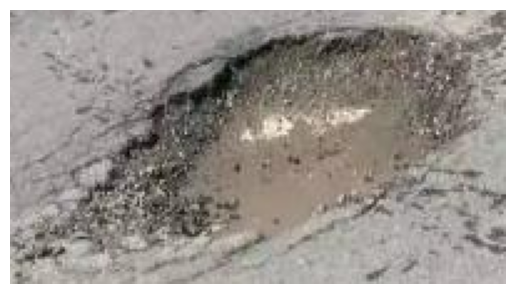

In [89]:
img = Image.open(photo_path).convert("RGB")

for box in boxes:
    x1, y1, x2, y2 = [int(v) for v in box.xyxy[0].tolist()]
    crop = img.crop((x1, y1, x2, y2))

    x = crop_transform(crop).unsqueeze(0).to(device)
    with torch.no_grad():
        scores = classifier(x)
    label = class_names[scores.argmax(1).item()]

    print("box:", (x1, y1, x2, y2), "yolo confidence:", round(box.conf[0].item(), 2), "severity:", label)

    plt.imshow(crop)
    plt.axis("off")
    plt.show()

## 7. Draw the boxes and severity labels on the photo

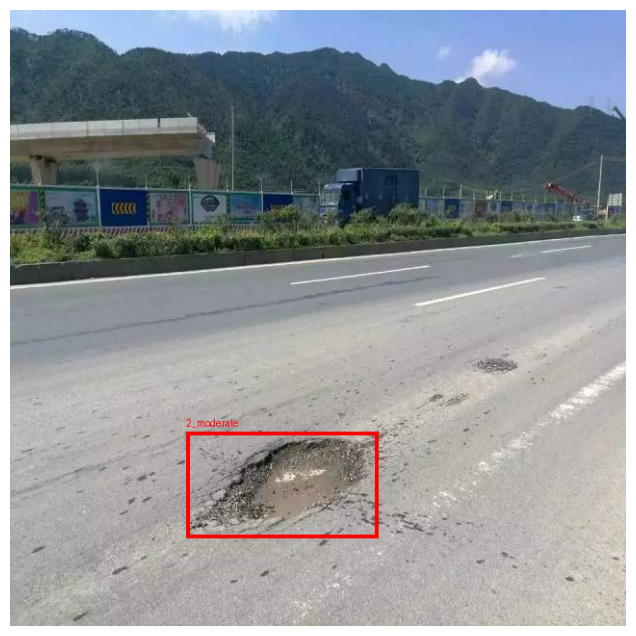

In [90]:
draw_img = img.copy()
draw = ImageDraw.Draw(draw_img)

for box in boxes:
    x1, y1, x2, y2 = [int(v) for v in box.xyxy[0].tolist()]
    crop = img.crop((x1, y1, x2, y2))

    x = crop_transform(crop).unsqueeze(0).to(device)
    with torch.no_grad():
        scores = classifier(x)
    label = class_names[scores.argmax(1).item()]

    draw.rectangle((x1, y1, x2, y2), outline="red", width=4)
    draw.text((x1, max(y1 - 15, 0)), label, fill="red")


plt.figure(figsize=(10,8))
plt.imshow(draw_img)
plt.axis("off")
plt.show()

## 8. Wrap everything in one function

In [91]:
def analyze_photo(path, conf=0.5):
    """Detect potholes in a photo, classify each one, and show the annotated photo."""
    img = Image.open(path).convert("RGB")
    results = yolo_model(path, conf=conf, verbose=False)
    boxes = results[0].boxes
    draw_img = img.copy()
    draw = ImageDraw.Draw(draw_img)

    for box in boxes:
        x1, y1, x2, y2 = [int(v) for v in box.xyxy[0].tolist()]
        crop = img.crop((x1, y1, x2, y2))
        x = crop_transform(crop).unsqueeze(0).to(device)
        with torch.no_grad():
            scores = classifier(x)
        label = class_names[scores.argmax(1).item()]

        draw.rectangle((x1, y1, x2, y2), outline="red", width=4)
        draw.text((x1, max(y1 - 15, 0)), label, fill="red")

    print(len(boxes), "pothole(s) found")

    plt.figure(figsize=(10, 8))
    plt.imshow(draw_img)
    plt.axis("off")
    plt.show()

## 9. Limitation: false positives at a low threshold
The detector was trained without negative examples. With `conf=0.2` it reports extra boxes (on other photos it flagged dark vegetation and shadows as potholes), which is why the default threshold is 0.5.

3 pothole(s) found


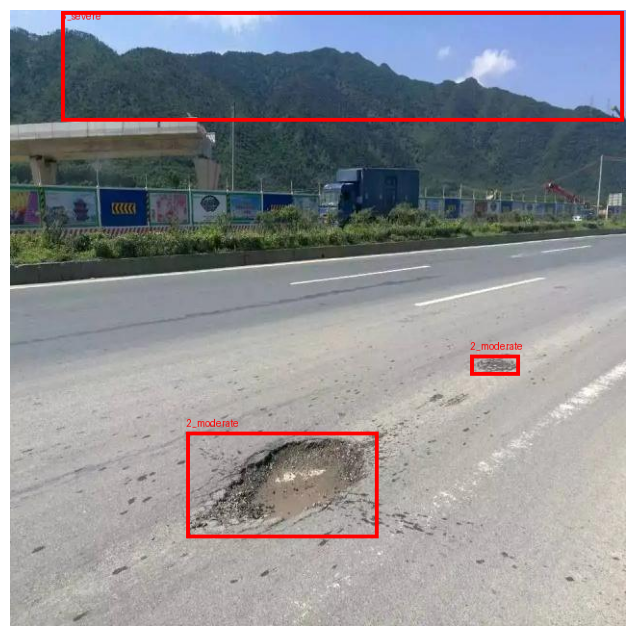

In [92]:
analyze_photo(photo_path, conf=0.2)